In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('data/clock/runtime.csv')
df.head()

,dataset,embedder,device,mean_runtime,std_runtime,total_runtime,n_samples,n_full_batches
0,ogbg-molmuv,chemeleon,cuda,9.881405,0.512977,91.966984,10000,9
1,ogbg-molmuv,coati,cuda,116.352131,0.711170,1082.938419,10000,9
2,ogbg-molmuv,AtomPair,cpu,1.274555,1.612154,11.939605,10000,9
3,ogbg-molmuv,AtomPair_count,cpu,0.821864,0.079381,7.722629,10000,9
4,ogbg-molmuv,ECFP,cpu,0.708762,0.047684,6.782019,10000,9


In [3]:
model_mapping = {
    'mol2vec': 'Mol2Vec',
    'coati': 'COATI',
    'CDDD': 'CDDD',
    'AtomPair': 'AtomPair',
    'AtomPair_count': 'AtomPair',
    'ECFP_count': 'ECFP',
    'ECFP': 'ECFP',
    'TT': 'TT',
    'TT_count': 'TT',
    'GraphMVP_CP-max': 'GraphMVP',
    'GraphMVP_CP-sum': 'GraphMVP',
    'GraphMVP_CP-mean': 'GraphMVP',
    'GraphMVP_AM-max': 'GraphMVP',
    'GraphMVP_AM-sum': 'GraphMVP',
    'GraphMVP_AM-mean': 'GraphMVP',
    'ChemBERTa-10M-MTR': 'ChemBERTa',
    'ChemBERTa-5M-MTR': 'ChemBERTa',
    'ChemBERTa-10M-MLM': 'ChemBERTa',
    'ChemBERTa-5M-MLM': 'ChemBERTa',
    'ChemBERTa-77M-MTR': 'ChemBERTa',
    'ChemBERTa-77M-MLM': 'ChemBERTa',
    'ChemFM-1B': 'ChemFM',
    'ChemFM-3B': 'ChemFM',
    'ChemGPT-4.7M': 'ChemGPT',
    'ChemGPT-19M': 'ChemGPT',
    'MoLFormer-XL-both-10pct': 'MoLFormer',
    'mol_r_tag_1024': 'MolR',
    'mol_r_sage_1024': 'MolR',
    'mol_r_gcn_1024': 'MolR',
    'mol_r_gat_1024': 'MolR',
    'chemformer_augment': 'ChemFormer',
    'chemformer_mask': 'ChemFormer',
    'chemformer_combined': 'ChemFormer',
    'SimSon': 'SimSon',
    'MolTransformer': 'MolTransformer',
    'CLAMP': 'CLAMP',
    'mat_masking_20M': 'MAT',
    'mat_masking_2M': 'MAT',
    'mat_masking_200k': 'MAT',
    'grover_base': 'Grover',
    'grover_large': 'Grover',
    'rmat_4M': 'RMAT',
    'GraphFP-C': 'GraphFP',
    'GraphFP-CP': 'GraphFP',
    'molbert': 'MolBERT',
    'GEM': 'GEM',
    'GNN-EP-sum': 'GIN',
    'GNN-Contextual-sum': 'GIN',
    'GNN-GPT_TNN-sum': 'GIN',
    'GNN-CP-sum': 'GIN',
    'GNN-GraphCL-sum': 'GIN',
    'GNN-IG-sum': 'GIN',
    'GNN-Motif-sum': 'GIN',
    'GNN-AM-sum': 'GIN',
    'unimolv1': 'UniMolv1',
    'unimolv2': 'UniMolv2',
    'SELFormer': 'SELFormer',
    'SELFormer-Lite': 'SELFormer',
    'mole': 'MolE',
    'mordred_2d': 'Mordred',
    'chemeleon': 'Chemeleon',
    'CLAMP_noleak': 'CLAMP',
}

In [8]:
df[df['family'] == 'GEM']

,dataset,embedder,device,mean_runtime,std_runtime,total_runtime,n_samples,n_full_batches,family
8,ogbg-molmuv,GEM,cpu,5329.101474,138.139132,49551.84375,10000,9,GEM


In [7]:
df[df['family'] == 'Mordred']

,dataset,embedder,device,mean_runtime,std_runtime,total_runtime,n_samples,n_full_batches,family
41,ogbg-molmuv,mordred_2d,cpu,187.370919,10.011422,1777.311362,10000,9,Mordred


In [4]:
df['family'] = df['embedder'].map(model_mapping)

In [5]:
df_best = df[
    df['mean_runtime'] == df.groupby(['dataset', 'family'])['mean_runtime'].transform('min')
]

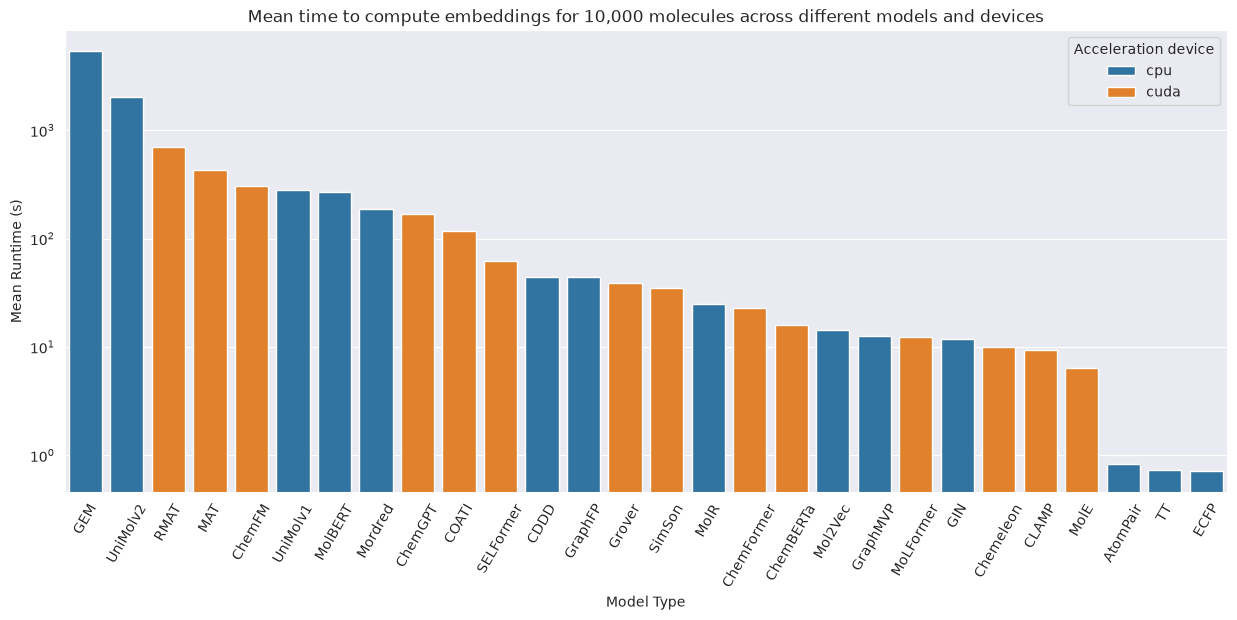

In [38]:
sns.set_style('darkgrid')

df_best = df_best.sort_values(by='mean_runtime', ascending=False)

sns.barplot(
    data=df_best,
    x='family',
    y='mean_runtime',
    hue='device',
    
)

plt.xticks(rotation=60)
plt.gcf().set_size_inches(15, 6)
plt.yscale('log')
plt.ylabel('Mean Runtime (s)')
plt.xlabel('Model Type')
plt.legend(title='Acceleration device', loc='upper right')
plt.title('Mean time to compute embeddings for 10,000 molecules across different models and devices')
_ = plt.show()

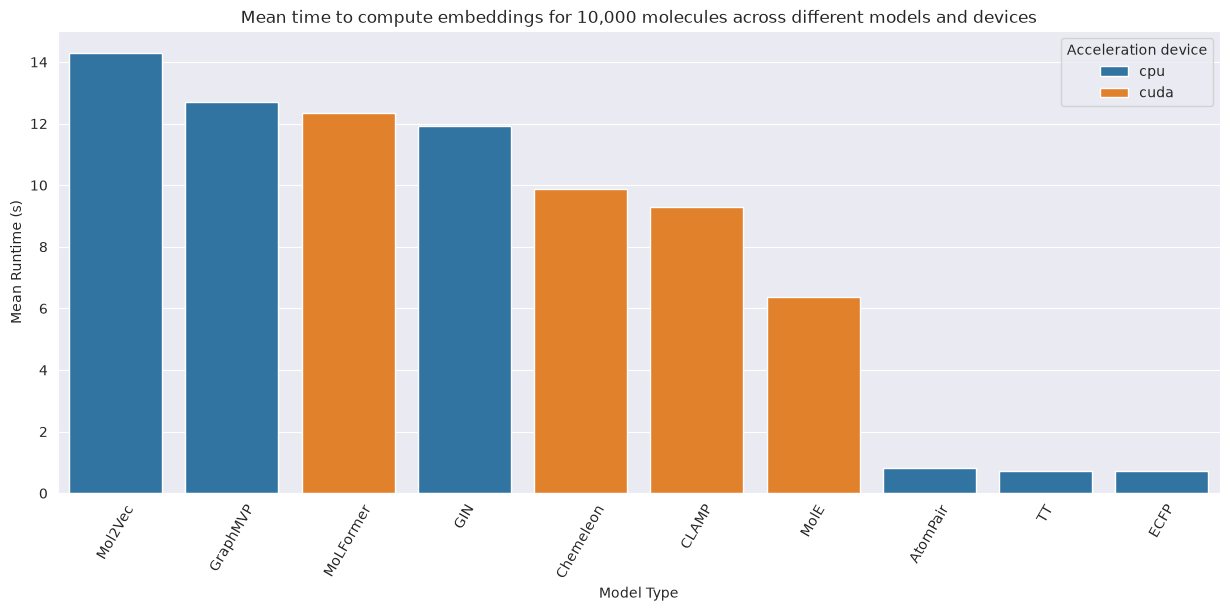

In [42]:
top10 = df_best.groupby('family')['mean_runtime'].mean().sort_values(ascending=True).head(10).index
top10 = df_best[df_best['family'].isin(top10)]

sns.set_style('darkgrid')

top10 = top10.sort_values(by='mean_runtime', ascending=False)

sns.barplot(
    data=top10,
    x='family',
    y='mean_runtime',
    hue='device',
    
)

plt.xticks(rotation=60)
plt.gcf().set_size_inches(15, 6)
# plt.yscale('log')
plt.ylabel('Mean Runtime (s)')
plt.xlabel('Model Type')
plt.legend(title='Acceleration device', loc='upper right')
plt.title('Mean time to compute embeddings for 10,000 molecules across different models and devices')
_ = plt.show()

In [34]:
dupes = df_best.groupby(['family', 'device']).size()
print(dupes[dupes > 1])

Series([], dtype: int64)


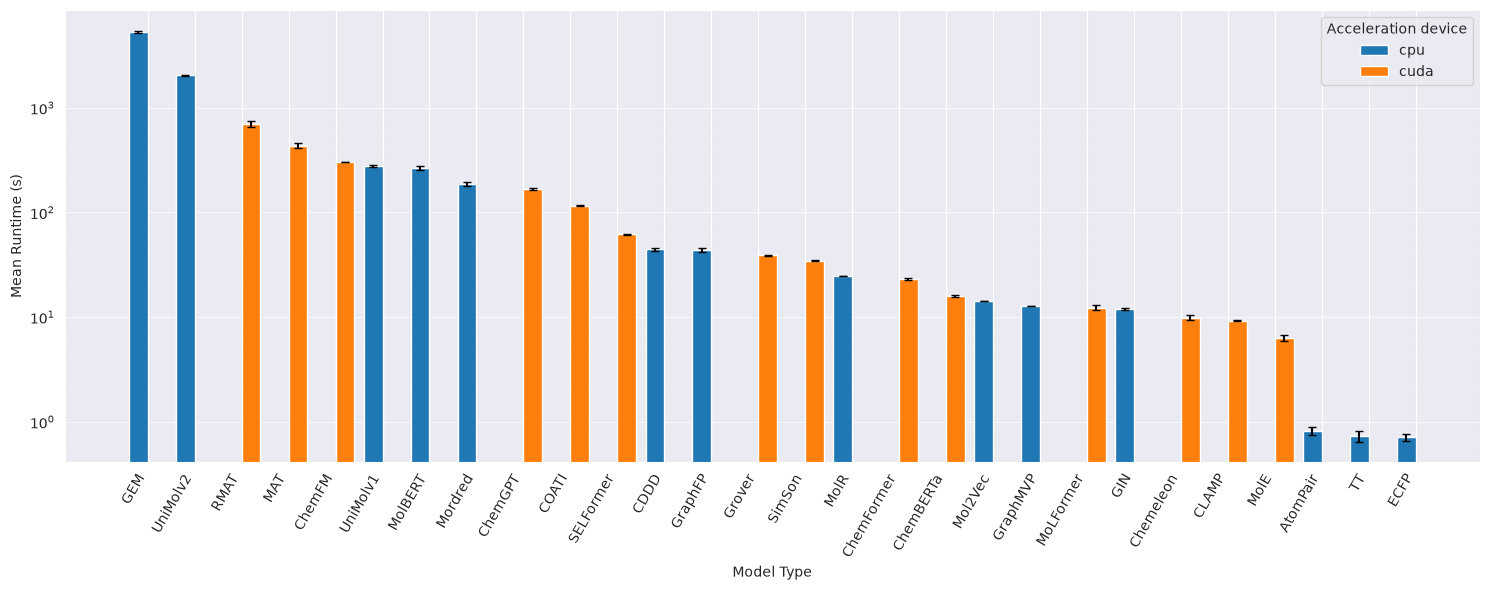

In [36]:
import numpy as np
import matplotlib.ticker as mticker

# --- aggregate explicitly, once, no ambiguity ---
summary = (
    df_best.groupby(['family', 'device'], as_index=False)
    .agg(mean_runtime=('mean_runtime', 'mean'), std_runtime=('std_runtime', 'mean'))
)

family_order = (
    summary.groupby('family')['mean_runtime'].mean()
    .sort_values(ascending=False)
    .index.tolist()
)
device_order = sorted(summary['device'].unique())

n_families = len(family_order)
n_devices = len(device_order)
bar_width = 0.8 / n_devices
x = np.arange(n_families)

fig, ax = plt.subplots(figsize=(15, 6))

pivot_mean = summary.pivot(index='family', columns='device', values='mean_runtime').reindex(family_order)[device_order]
pivot_std  = summary.pivot(index='family', columns='device', values='std_runtime').reindex(family_order)[device_order]

for i, device in enumerate(device_order):
    offset = (i - (n_devices - 1) / 2) * bar_width
    ax.bar(
        x + offset,
        pivot_mean[device].values,
        width=bar_width,
        label=device,
        yerr=pivot_std[device].values,
        capsize=3,
        ecolor='black',
    )

ax.set_xticks(x)
ax.set_xticklabels(family_order, rotation=60, ha='right')
ax.set_yscale('log')
ax.set_ylabel('Mean Runtime (s)')
ax.set_xlabel('Model Type')
ax.legend(title='Acceleration device', loc='upper right')

# --- minor gridlines on log scale ---
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10, subs=[0.2, 0.4, 0.6, 0.8], numticks=12))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(which='minor', axis='y', linestyle=':', linewidth=0.5, alpha=0.5)
ax.grid(which='major', axis='y', linestyle='-', linewidth=0.8, alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
_ri